In [1]:
import polars as pl
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

print("Semua library berhasil diimpor.")
print("Versi Polars:", pl.__version__)

Semua library berhasil diimpor.
Versi Polars: 2.0.0


In [2]:
DATA_PATH = "/home/jovyan/work/data/raw/cosmopedia_id.csv"

OUTPUT_DIR = Path("/home/jovyan/work/data/processed")
OUTPUT_PATH = OUTPUT_DIR / "cosmopedia_id_clean.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

file = Path(DATA_PATH)

if file.exists():
    print("Dataset ditemukan.")
    print("Lokasi:", DATA_PATH)
    print(f"Ukuran file: {file.stat().st_size / (1024**2):.2f} MB")
else:
    raise FileNotFoundError("Dataset tidak ditemukan. Periksa kembali DATA_PATH.")

Dataset ditemukan.
Lokasi: /home/jovyan/work/data/raw/cosmopedia_id.csv
Ukuran file: 554.81 MB


In [3]:
df = pl.read_csv(
    DATA_PATH,
    infer_schema_length=10000,
    null_values=["", "NULL", "null", "None"]
)

print("Dataset berhasil dibaca.")
print("Jumlah baris:", df.height)
print("Jumlah kolom:", df.width)

display(df.head(10))

Dataset berhasil dibaca.
Jumlah baris: 120068
Jumlah kolom: 9


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""
28,"""Berikut kutipan tentang invest…","""Di negeri yang luas, seorang b…",57,"""children""","""story""","""fineweb""",6,"""2026-02-18 08:19:23"""
29,"""Berikut kutipan tentang kesela…","""Alice: Hei Bob, kalau jalan di…",61,"""children""","""dialogue""","""fineweb""",7,"""2026-02-18 08:19:23"""
30,"""Berikut kutipan tentang makana…","""Emma suka makanan manis. Bu Gu…",64,"""children""","""story""","""fineweb""",8,"""2026-02-18 08:19:23"""
31,"""Berikut kutipan tentang penyem…","""Alice: Aku sering susah tidur …",48,"""children""","""dialogue""","""fineweb""",9,"""2026-02-18 08:19:23"""


In [4]:
# Memeriksa Struktur Dataset
print("Struktur Dataset:")
print(df.schema)

print("\nInformasi Jumlah Baris dan Kolom:")
print(f"Baris  : {df.height}")
print(f"Kolom  : {df.width}")

Struktur Dataset:
Schema({'id': Int64, 'prompt': String, 'text': String, 'token_length': Int64, 'audience': String, 'format': String, 'seed_data': String, 'datasheet_global_id': Int64, 'created_at': String})

Informasi Jumlah Baris dan Kolom:
Baris  : 120068
Kolom  : 9


In [5]:
# Memeriksa Missing Values
missing_before = df.null_count()

print("Jumlah Missing Values Sebelum Cleaning:")
display(missing_before)

Jumlah Missing Values Sebelum Cleaning:


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,1,1,1,0,0


In [6]:
# Menghitung Persentase Missing Values
missing_percentage = (
    missing_before
    .transpose(
        include_header=True,
        header_name="kolom",
        column_names=["jumlah_missing"]
    )
    .with_columns(
        (
            pl.col("jumlah_missing") / df.height * 100
        ).alias("persentase_missing")
    )
)

display(missing_percentage)

kolom,jumlah_missing,persentase_missing
str,u32,f64
"""id""",0,0.0
"""prompt""",0,0.0
"""text""",0,0.0
"""token_length""",0,0.0
"""audience""",1,0.000833
"""format""",1,0.000833
"""seed_data""",1,0.000833
"""datasheet_global_id""",0,0.0
"""created_at""",0,0.0


In [7]:
# Memeriksa Data Duplikat
# Menghitung duplikasi seluruh baris
duplicate_rows = df.height - df.unique().height

print("Jumlah baris duplikat identik:", duplicate_rows)

# Memeriksa ID yang muncul lebih dari sekali
duplicate_ids = (
    df.group_by("id")
    .agg(pl.len().alias("jumlah"))
    .filter(pl.col("jumlah") > 1)
)

print("Jumlah ID yang muncul lebih dari sekali:", duplicate_ids.height)

display(duplicate_ids.head(10))

Jumlah baris duplikat identik: 0
Jumlah ID yang muncul lebih dari sekali: 0


id,jumlah
i64,u32


In [8]:
# Memeriksa Nilai Kosong pada Kolom Teks
text_columns = [
    "prompt",
    "text",
    "audience",
    "format",
    "seed_data"
]

empty_report = []

for column in text_columns:
    empty_count = (
        df.select(
            (pl.col(column).str.strip_chars() == "")
            .fill_null(False)
            .sum()
        ).item()
    )

    empty_report.append({
        "kolom": column,
        "jumlah_string_kosong": empty_count
    })

display(pl.DataFrame(empty_report))

kolom,jumlah_string_kosong
str,i64
"""prompt""",0
"""text""",0
"""audience""",0
"""format""",0
"""seed_data""",0


In [9]:
# Membersihkan Spasi dan String Kosong
df_clean = df.with_columns([
    pl.when(
        pl.col(column).str.strip_chars() == ""
    )
    .then(None)
    .otherwise(
        pl.col(column).str.strip_chars()
    )
    .alias(column)

    for column in text_columns
])

print("Pembersihan spasi dan string kosong selesai.")

display(df_clean.head(10))

Pembersihan spasi dan string kosong selesai.


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""
28,"""Berikut kutipan tentang invest…","""Di negeri yang luas, seorang b…",57,"""children""","""story""","""fineweb""",6,"""2026-02-18 08:19:23"""
29,"""Berikut kutipan tentang kesela…","""Alice: Hei Bob, kalau jalan di…",61,"""children""","""dialogue""","""fineweb""",7,"""2026-02-18 08:19:23"""
30,"""Berikut kutipan tentang makana…","""Emma suka makanan manis. Bu Gu…",64,"""children""","""story""","""fineweb""",8,"""2026-02-18 08:19:23"""
31,"""Berikut kutipan tentang penyem…","""Alice: Aku sering susah tidur …",48,"""children""","""dialogue""","""fineweb""",9,"""2026-02-18 08:19:23"""


In [10]:
# Menangani Missing Values
before_drop = df_clean.height

df_clean = df_clean.drop_nulls(
    subset=["id", "prompt", "text"]
)

after_drop = df_clean.height

print("Jumlah baris sebelum penanganan:", before_drop)
print("Jumlah baris setelah penanganan:", after_drop)
print("Jumlah baris dihapus:", before_drop - after_drop)

Jumlah baris sebelum penanganan: 120068
Jumlah baris setelah penanganan: 120068
Jumlah baris dihapus: 0


In [11]:
# Menghapus Data Duplikat
before_duplicate = df_clean.height

df_clean = df_clean.unique(
    maintain_order=True
)

after_duplicate = df_clean.height

print("Jumlah baris sebelum menghapus duplikat:", before_duplicate)
print("Jumlah baris setelah menghapus duplikat:", after_duplicate)
print("Jumlah duplikat yang dihapus:", before_duplicate - after_duplicate)

Jumlah baris sebelum menghapus duplikat: 120068
Jumlah baris setelah menghapus duplikat: 120068
Jumlah duplikat yang dihapus: 0


In [12]:
# Memeriksa Tipe Data
print("Tipe Data Setelah Cleaning:")

for column, dtype in df_clean.schema.items():
    print(f"{column}: {dtype}")

Tipe Data Setelah Cleaning:
id: Int64
prompt: String
text: String
token_length: Int64
audience: String
format: String
seed_data: String
datasheet_global_id: Int64
created_at: String


In [13]:
# Memeriksa Statistik Dataset Setelah Cleaning
print("Statistik Dataset Setelah Cleaning:")

display(df_clean.describe())

Statistik Dataset Setelah Cleaning:


statistic,id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
str,f64,str,str,f64,str,str,str,f64,str
"""count""",120068.0,"""120068""","""120068""",120068.0,"""120067""","""120067""","""120067""",120068.0,"""120068"""
"""null_count""",0.0,"""0""","""0""",0.0,"""1""","""1""","""1""",0.0,"""0"""
"""mean""",60057.499217,null,null,1187.939651,null,null,null,60034.5,null
"""std""",34660.791753,null,null,194.61858,null,null,null,34660.790398,null
"""min""",1.0,"""Berikut adalah cuplikan dari h…","""**1.1 Apa itu Ilmu Data?** Ba…",36.0,"""children""","""Dialogue""","""fineweb""",1.0,"""2026-02-18 07:35:54"""
"""25%""",30041.0,null,null,1065.0,null,null,null,30018.0,null
"""50%""",60058.0,null,null,1168.0,null,null,null,60035.0,null
"""75%""",90074.0,null,null,1296.0,null,null,null,90051.0,null
"""max""",120091.0,"""Write an educational story (3-…","""अगर आपको उchcha madhyamik stan…",2787.0,"""young_children""","""textbook_unconditionned_topic""","""ultrachat""",120068.0,"""2026-03-06 03:44:48"""


In [14]:
# Memeriksa Missing Values Setelah Cleaning
missing_after = df_clean.null_count()

print("Missing Values Setelah Cleaning:")
display(missing_after)

Missing Values Setelah Cleaning:


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,1,1,1,0,0


In [15]:
# Perbandingan Kondisi Dataset Sebelum dan Sesudah Cleaning
comparison = pl.DataFrame({
    "Keterangan": [
        "Jumlah Baris",
        "Jumlah Kolom",
        "Jumlah Baris Duplikat Identik",
        "Jumlah Missing Values"
    ],
    "Sebelum Cleaning": [
        df.height,
        df.width,
        duplicate_rows,
        sum(df.null_count().row(0))
    ],
    "Sesudah Cleaning": [
        df_clean.height,
        df_clean.width,
        df_clean.height - df_clean.unique().height,
        sum(df_clean.null_count().row(0))
    ]
})

display(comparison)

Keterangan,Sebelum Cleaning,Sesudah Cleaning
str,i64,i64
"""Jumlah Baris""",120068,120068
"""Jumlah Kolom""",9,9
"""Jumlah Baris Duplikat Identik""",0,0
"""Jumlah Missing Values""",3,3


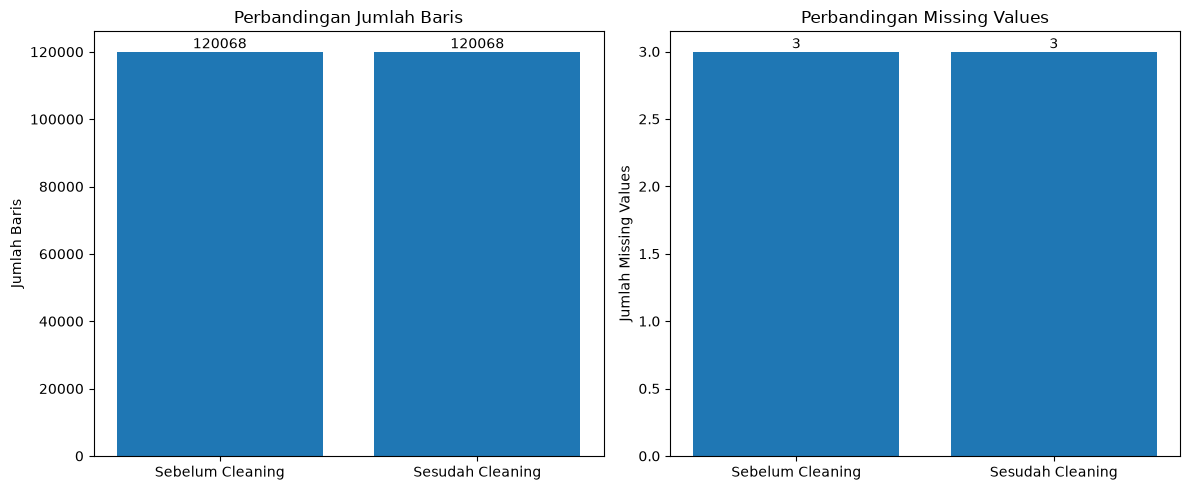

In [16]:
# Visualisasi Perbandingan Data
labels = ["Sebelum Cleaning", "Sesudah Cleaning"]

jumlah_baris = [df.height, df_clean.height]

jumlah_missing = [
    sum(df.null_count().row(0)),
    sum(df_clean.null_count().row(0))
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafik jumlah baris
axes[0].bar(labels, jumlah_baris)
axes[0].set_title("Perbandingan Jumlah Baris")
axes[0].set_ylabel("Jumlah Baris")

for i, value in enumerate(jumlah_baris):
    axes[0].text(i, value, str(value), ha="center", va="bottom")

# Grafik missing values
axes[1].bar(labels, jumlah_missing)
axes[1].set_title("Perbandingan Missing Values")
axes[1].set_ylabel("Jumlah Missing Values")

for i, value in enumerate(jumlah_missing):
    axes[1].text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [17]:
# Validasi Menggunakan DuckDB
con = duckdb.connect()

result = con.execute("""
    SELECT
        COUNT(*) AS jumlah_baris,
        COUNT(DISTINCT id) AS jumlah_id_unik,
        COUNT(*) - COUNT(DISTINCT id) AS jumlah_id_berulang
    FROM df_clean
""").fetchdf()

display(result)

,jumlah_baris,jumlah_id_unik,jumlah_id_berulang
0,120068,120068,0


In [18]:
# Menyimpan Dataset Hasil Cleaning
df_clean.write_parquet(
    OUTPUT_PATH,
    compression="zstd"
)

print("Dataset hasil cleaning berhasil disimpan.")
print("Lokasi:", OUTPUT_PATH)
print(f"Ukuran file: {OUTPUT_PATH.stat().st_size / (1024**2):.2f} MB")

Dataset hasil cleaning berhasil disimpan.
Lokasi: /home/jovyan/work/data/processed/cosmopedia_id_clean.parquet
Ukuran file: 154.10 MB


In [19]:
if OUTPUT_PATH.exists():
    df_check = pl.read_parquet(OUTPUT_PATH)

    print("Validasi penyimpanan berhasil.")
    print("Jumlah baris:", df_check.height)
    print("Jumlah kolom:", df_check.width)

    display(df_check.head(10))
else:
    print("File hasil cleaning belum ditemukan.")

Validasi penyimpanan berhasil.
Jumlah baris: 120068
Jumlah kolom: 9


id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""
28,"""Berikut kutipan tentang invest…","""Di negeri yang luas, seorang b…",57,"""children""","""story""","""fineweb""",6,"""2026-02-18 08:19:23"""
29,"""Berikut kutipan tentang kesela…","""Alice: Hei Bob, kalau jalan di…",61,"""children""","""dialogue""","""fineweb""",7,"""2026-02-18 08:19:23"""
30,"""Berikut kutipan tentang makana…","""Emma suka makanan manis. Bu Gu…",64,"""children""","""story""","""fineweb""",8,"""2026-02-18 08:19:23"""
31,"""Berikut kutipan tentang penyem…","""Alice: Aku sering susah tidur …",48,"""children""","""dialogue""","""fineweb""",9,"""2026-02-18 08:19:23"""


### Penanganan Missing Values

Berdasarkan hasil pemeriksaan, ditemukan tiga missing values pada dataset, yaitu masing-masing satu nilai pada kolom `audience`, `format`, dan `seed_data`. Ketiga kolom tersebut merupakan atribut metadata yang tidak termasuk informasi utama dalam proses pengolahan teks.

Oleh karena itu, missing values pada ketiga kolom tersebut dipertahankan dan tidak dilakukan penghapusan baris maupun pengisian nilai. Keputusan ini dilakukan untuk menghindari hilangnya informasi yang masih tersedia pada kolom lainnya.

## Kesimpulan Data Cleaning

Berdasarkan proses data cleaning yang telah dilakukan, dataset Cosmopedia Indonesia berhasil melalui beberapa tahapan pembersihan data.

Tahapan tersebut meliputi pemeriksaan missing values, identifikasi data duplikat, pembersihan spasi pada kolom teks, penanganan nilai kosong pada kolom utama, serta pemeriksaan tipe data.

Baris yang tidak memiliki informasi utama berupa id, prompt, atau text dihapus. Selain itu, baris yang memiliki seluruh nilai identik juga dihapus untuk menghindari duplikasi data. Nilai kosong pada kolom metadata tetap dipertahankan agar informasi yang tersedia tidak hilang.

Dataset hasil cleaning kemudian disimpan dalam format Parquet pada folder data/processed/ dengan nama cosmopedia_id_clean.parquet.

Hasil data cleaning ini akan digunakan sebagai dasar untuk tahap Exploratory Data Analysis (EDA) dan analisis lebih lanjut.m